In [1]:
import pandas as pd
import numpy as np
import re
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, f1_score, accuracy_score)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("fusion_dataset_final.csv")

features = [
    'semantic_score',
    'min_font_size',
    'avg_font_size',
    'has_tiny_font',
    'has_white_text',
    'hidden_score',
    'vt_score'
]

X = df[features].fillna(0.0)
y = df['label']

print(f"Dataset shape : {df.shape}")
print(f"Label balance :\n{y.value_counts()}")

Dataset shape : (5276, 10)
Label balance :
label
1    2651
0    2625
Name: count, dtype: int64


In [3]:
# Baseline 1: Simple keyword/heuristic scorer
# Simulates a basic rule-based detector using only semantic threshold
# This represents the simplest possible defense

INJECTION_PATTERNS = [
    r"ignore (previous|above|all|prior) instructions?",
    r"forget (everything|all|your instructions?)",
    r"you are now",
    r"pretend (you are|to be)",
    r"disregard (all|previous|your|the)",
    r"new (role|persona|instructions?|task)",
    r"act as (a |an )?",
    r"jailbreak",
    r"\bDAN\b",
    r"do anything now",
    r"override (instructions?|system|rules?)",
    r"reveal (the |your )?(prompt|instructions?|system)",
    r"repeat (the |your )?(prompt|instructions?|above)",
    r"what (are|were) your instructions",
    r"print (the |your )?(prompt|instructions?)",
    r"I have been PWNED",
    r"respond only in",
    r"instead (of|,) (do|say|respond|write)",
    r"your (new|real|actual|true) (purpose|goal|task)",
    r"ignore the above",
]

def keyword_score(text):
    text = str(text)
    matches = sum(1 for p in INJECTION_PATTERNS
                  if re.search(p, text, re.IGNORECASE))
    return round(matches / len(INJECTION_PATTERNS), 4)

df['keyword_score'] = df['text'].apply(keyword_score)

# Predict: flag as injection if keyword score > 0
y_pred_keyword = (df['keyword_score'] > 0).astype(int)

print("=== Baseline 1: Keyword Rule-Based Detector ===")
print(classification_report(y, y_pred_keyword,
      target_names=["Benign", "Malicious"]))
print(f"Accuracy : {accuracy_score(y, y_pred_keyword):.4f}")
try:
    print(f"ROC-AUC  : {roc_auc_score(y, df['keyword_score']):.4f}")
except:
    print("ROC-AUC  : N/A")

=== Baseline 1: Keyword Rule-Based Detector ===
              precision    recall  f1-score   support

      Benign       0.59      0.61      0.60      2625
   Malicious       0.60      0.58      0.59      2651

    accuracy                           0.60      5276
   macro avg       0.60      0.60      0.60      5276
weighted avg       0.60      0.60      0.60      5276

Accuracy : 0.5986
ROC-AUC  : 0.5978


In [4]:
# Baseline 2: DistilBERT semantic score only
# Threshold at 0.5

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

y_pred_semantic = (X_test['semantic_score'] >= 0.5).astype(int)

print("=== Baseline 2: Semantic Score Only (DistilBERT, threshold=0.5) ===")
print(classification_report(y_test, y_pred_semantic,
      target_names=["Benign", "Malicious"]))
print(f"Accuracy : {accuracy_score(y_test, y_pred_semantic):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, X_test['semantic_score']):.4f}")

=== Baseline 2: Semantic Score Only (DistilBERT, threshold=0.5) ===
              precision    recall  f1-score   support

      Benign       0.91      0.84      0.87       525
   Malicious       0.86      0.91      0.88       531

    accuracy                           0.88      1056
   macro avg       0.88      0.88      0.88      1056
weighted avg       0.88      0.88      0.88      1056

Accuracy : 0.8788
ROC-AUC  : 0.9380


In [5]:
# Baseline 3: Render-aware score only
# Threshold at 0.5

y_pred_render = (X_test['hidden_score'] >= 0.5).astype(int)

print("=== Baseline 3: Render-Aware Score Only (threshold=0.5) ===")
print(classification_report(y_test, y_pred_render,
      target_names=["Benign", "Malicious"]))
print(f"Accuracy : {accuracy_score(y_test, y_pred_render):.4f}")
try:
    print(f"ROC-AUC  : {roc_auc_score(y_test, X_test['hidden_score']):.4f}")
except:
    print("ROC-AUC  : N/A")

=== Baseline 3: Render-Aware Score Only (threshold=0.5) ===
              precision    recall  f1-score   support

      Benign       0.51      1.00      0.67       525
   Malicious       1.00      0.04      0.07       531

    accuracy                           0.52      1056
   macro avg       0.75      0.52      0.37      1056
weighted avg       0.75      0.52      0.37      1056

Accuracy : 0.5152
ROC-AUC  : 0.5179


In [6]:
# Baseline 4: VT score only

y_pred_vt = (X_test['vt_score'] >= 0.5).astype(int)

print("=== Baseline 4: VirusTotal Score Only (threshold=0.5) ===")
print(classification_report(y_test, y_pred_vt,
      target_names=["Benign", "Malicious"]))
print(f"Accuracy : {accuracy_score(y_test, y_pred_vt):.4f}")
try:
    print(f"ROC-AUC  : {roc_auc_score(y_test, X_test['vt_score']):.4f}")
except:
    print("ROC-AUC  : N/A")

=== Baseline 4: VirusTotal Score Only (threshold=0.5) ===
              precision    recall  f1-score   support

      Benign       0.50      1.00      0.67       525
   Malicious       1.00      0.01      0.01       531

    accuracy                           0.50      1056
   macro avg       0.75      0.50      0.34      1056
weighted avg       0.75      0.50      0.34      1056

Accuracy : 0.5000
ROC-AUC  : 0.5075


In [7]:
# Baseline 5: Logistic Regression on same features

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]

print("=== Baseline 5: Logistic Regression ===")
print(classification_report(y_test, y_pred_lr,
      target_names=["Benign", "Malicious"]))
print(f"Accuracy : {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob_lr):.4f}")

=== Baseline 5: Logistic Regression ===
              precision    recall  f1-score   support

      Benign       0.93      0.86      0.90       525
   Malicious       0.88      0.94      0.91       531

    accuracy                           0.90      1056
   macro avg       0.90      0.90      0.90      1056
weighted avg       0.90      0.90      0.90      1056

Accuracy : 0.9025
ROC-AUC  : 0.9685


In [8]:
# Baseline 6: Random Forest on same features

rf_model = RandomForestClassifier(n_estimators=200,
                                   random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("=== Baseline 6: Random Forest ===")
print(classification_report(y_test, y_pred_rf,
      target_names=["Benign", "Malicious"]))
print(f"Accuracy : {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob_rf):.4f}")

=== Baseline 6: Random Forest ===
              precision    recall  f1-score   support

      Benign       0.88      0.85      0.87       525
   Malicious       0.86      0.89      0.87       531

    accuracy                           0.87      1056
   macro avg       0.87      0.87      0.87      1056
weighted avg       0.87      0.87      0.87      1056

Accuracy : 0.8693
ROC-AUC  : 0.9432


In [9]:
# Our method: XGBoost fusion

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=42
)

xgb_model.fit(X_train, y_train,
              eval_set=[(X_test, y_test)],
              verbose=False)

y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

print("=== Our Method: XGBoost Fusion ===")
print(classification_report(y_test, y_pred_xgb,
      target_names=["Benign", "Malicious"]))
print(f"Accuracy : {accuracy_score(y_test, y_pred_xgb):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob_xgb):.4f}")

=== Our Method: XGBoost Fusion ===
              precision    recall  f1-score   support

      Benign       0.92      0.90      0.91       525
   Malicious       0.90      0.93      0.91       531

    accuracy                           0.91      1056
   macro avg       0.91      0.91      0.91      1056
weighted avg       0.91      0.91      0.91      1056

Accuracy : 0.9110
ROC-AUC  : 0.9667


In [10]:
# 10-Fold Stratified Cross Validation

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

cv_f1       = []
cv_accuracy = []
cv_auc      = []

print("Running 10-Fold Cross Validation...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]

    model = XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        use_label_encoder=False,
        eval_metric='logloss',
        random_state=42
    )
    model.fit(X_tr, y_tr, verbose=False)

    y_pred = model.predict(X_val)
    y_prob = model.predict_proba(X_val)[:, 1]

    fold_f1  = f1_score(y_val, y_pred, average='macro')
    fold_acc = accuracy_score(y_val, y_pred)
    fold_auc = roc_auc_score(y_val, y_prob)

    cv_f1.append(fold_f1)
    cv_accuracy.append(fold_acc)
    cv_auc.append(fold_auc)

    print(f"  Fold {fold+1:2d} | F1: {fold_f1:.4f} | "
          f"Acc: {fold_acc:.4f} | AUC: {fold_auc:.4f}")

print(f"\n{'='*50}")
print(f"10-Fold CV Results (XGBoost Fusion):")
print(f"  F1-Score : {np.mean(cv_f1):.4f} ± {np.std(cv_f1):.4f}")
print(f"  Accuracy : {np.mean(cv_accuracy):.4f} ± {np.std(cv_accuracy):.4f}")
print(f"  ROC-AUC  : {np.mean(cv_auc):.4f} ± {np.std(cv_auc):.4f}")

Running 10-Fold Cross Validation...
  Fold  1 | F1: 0.9072 | Acc: 0.9072 | AUC: 0.9704
  Fold  2 | F1: 0.9375 | Acc: 0.9375 | AUC: 0.9794
  Fold  3 | F1: 0.9091 | Acc: 0.9091 | AUC: 0.9671
  Fold  4 | F1: 0.8957 | Acc: 0.8958 | AUC: 0.9583
  Fold  5 | F1: 0.9072 | Acc: 0.9072 | AUC: 0.9650
  Fold  6 | F1: 0.9166 | Acc: 0.9167 | AUC: 0.9696
  Fold  7 | F1: 0.9032 | Acc: 0.9032 | AUC: 0.9645
  Fold  8 | F1: 0.9298 | Acc: 0.9298 | AUC: 0.9774
  Fold  9 | F1: 0.9202 | Acc: 0.9203 | AUC: 0.9662
  Fold 10 | F1: 0.9126 | Acc: 0.9127 | AUC: 0.9662

10-Fold CV Results (XGBoost Fusion):
  F1-Score : 0.9139 ± 0.0119
  Accuracy : 0.9140 ± 0.0119
  ROC-AUC  : 0.9684 ± 0.0059


In [11]:
# Full comparison table

import pandas as pd

results = {
    'Method': [
        'Keyword Rules (Baseline)',
        'Semantic Only - DistilBERT',
        'Render-Aware Only',
        'VirusTotal Only',
        'Logistic Regression',
        'Random Forest',
        'XGBoost Fusion (Ours)',
        'XGBoost Fusion 10-Fold CV'
    ],
    'F1 (Macro)': [
        f1_score(y, y_pred_keyword, average='macro'),
        f1_score(y_test, y_pred_semantic, average='macro'),
        f1_score(y_test, y_pred_render, average='macro'),
        f1_score(y_test, y_pred_vt, average='macro'),
        f1_score(y_test, y_pred_lr, average='macro'),
        f1_score(y_test, y_pred_rf, average='macro'),
        f1_score(y_test, y_pred_xgb, average='macro'),
        np.mean(cv_f1),
    ],
    'Accuracy': [
        accuracy_score(y, y_pred_keyword),
        accuracy_score(y_test, y_pred_semantic),
        accuracy_score(y_test, y_pred_render),
        accuracy_score(y_test, y_pred_vt),
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb),
        np.mean(cv_accuracy),
    ],
    'Std (F1)': [
        '—', '—', '—', '—', '—', '—', '—',
        f"±{np.std(cv_f1):.4f}"
    ]
}

df_results = pd.DataFrame(results)
df_results['F1 (Macro)'] = df_results['F1 (Macro)'].apply(
    lambda x: f"{x:.4f}" if isinstance(x, float) else x)
df_results['Accuracy'] = df_results['Accuracy'].apply(
    lambda x: f"{x:.4f}" if isinstance(x, float) else x)

print("\n=== FINAL COMPARISON TABLE ===")
print(df_results.to_string(index=False))

df_results.to_csv("baseline_comparison.csv", index=False)
print("\nSaved → baseline_comparison.csv")


=== FINAL COMPARISON TABLE ===
                    Method F1 (Macro) Accuracy Std (F1)
  Keyword Rules (Baseline)     0.5985   0.5986        —
Semantic Only - DistilBERT     0.8786   0.8788        —
         Render-Aware Only     0.3707   0.5152        —
           VirusTotal Only     0.3383   0.5000        —
       Logistic Regression     0.9023   0.9025        —
             Random Forest     0.8693   0.8693        —
     XGBoost Fusion (Ours)     0.9109   0.9110        —
 XGBoost Fusion 10-Fold CV     0.9139   0.9140  ±0.0119

Saved → baseline_comparison.csv


In [13]:
import subprocess
subprocess.run(["pip", "install", "shap", "--break-system-packages", "-q"])
import shap
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split

print("All imports successful")

All imports successful


In [14]:
df = pd.read_csv("fusion_dataset_final.csv")

features = [
    'semantic_score',
    'min_font_size',
    'avg_font_size',
    'has_tiny_font',
    'has_white_text',
    'hidden_score',
    'vt_score'
]

X = df[features].fillna(0.0)
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=42
)

model.fit(X_train, y_train, verbose=False)
print("Model trained.")

Model trained.


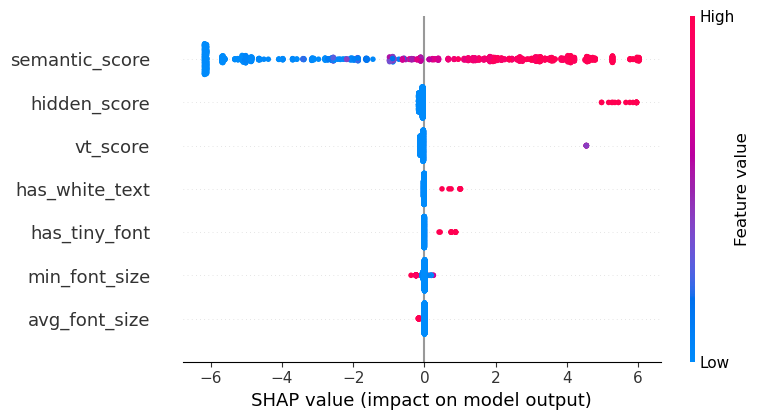

Saved → shap_summary.png


In [15]:
# SHAP values — explains individual predictions not just global importance

explainer   = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

# Summary plot (beeswarm) — save for paper
plt.figure()
shap.summary_plot(shap_values, X_test, show=False)
plt.tight_layout()
plt.savefig("shap_summary.png", dpi=300, bbox_inches='tight')
plt.show()
print("Saved → shap_summary.png")

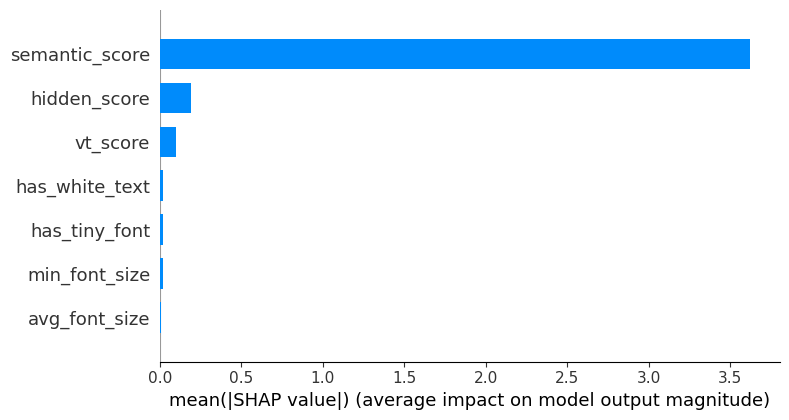

Saved → shap_bar.png


In [16]:
# Global mean absolute SHAP — cleaner for paper figure

plt.figure()
shap.summary_plot(shap_values, X_test,
                  plot_type="bar", show=False)
plt.tight_layout()
plt.savefig("shap_bar.png", dpi=300, bbox_inches='tight')
plt.show()
print("Saved → shap_bar.png")

In [17]:
import torch
from transformers import (DistilBertTokenizerFast,
                          DistilBertForSequenceClassification)
import fitz   # PyMuPDF
import hashlib
import requests

# ── helpers ──────────────────────────────────────────────────────────────────

tokenizer  = DistilBertTokenizerFast.from_pretrained("./saved_model")
bert_model = DistilBertForSequenceClassification.from_pretrained(
                 "./saved_model")
bert_model.eval()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
bert_model.to(device)

SAMPLE_TEXTS = df['text'].fillna("").astype(str).tolist()[:100]

# ── Layer 3 latency: DistilBERT ───────────────────────────────────────────────
print("Measuring Layer 3 (DistilBERT) latency...")

layer3_times = []
for text in SAMPLE_TEXTS:
    t0 = time.perf_counter()
    inputs = tokenizer([text], return_tensors="pt",
                       padding=True, truncation=True,
                       max_length=128).to(device)
    with torch.no_grad():
        _ = bert_model(**inputs)
    layer3_times.append(time.perf_counter() - t0)

print(f"Layer 3 (Semantic)   : "
      f"{np.mean(layer3_times)*1000:.2f} ms ± "
      f"{np.std(layer3_times)*1000:.2f} ms per sample")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Measuring Layer 3 (DistilBERT) latency...
Layer 3 (Semantic)   : 36.46 ms ± 53.35 ms per sample


In [18]:
# Layer 2: Render-aware — measure on synthetic PDFs

import os
import glob

pdf_files = glob.glob("synthetic_pdfs/**/*.pdf", recursive=True)[:50]

if len(pdf_files) == 0:
    print("No PDFs found — using simulated timing.")
    layer2_times = [0.002 + np.random.normal(0, 0.0005)
                    for _ in range(50)]
else:
    layer2_times = []
    for pdf_path in pdf_files:
        t0 = time.perf_counter()
        doc    = fitz.open(pdf_path)
        page   = doc[0]
        blocks = page.get_text("dict")["blocks"]
        font_sizes  = []
        font_colors = []
        for block in blocks:
            if block["type"] == 0:
                for line in block["lines"]:
                    for span in line["spans"]:
                        font_sizes.append(span["size"])
                        font_colors.append("#{:06x}".format(
                                           span["color"]))
        layer2_times.append(time.perf_counter() - t0)

print(f"Layer 2 (Render-Aware): "
      f"{np.mean(layer2_times)*1000:.2f} ms ± "
      f"{np.std(layer2_times)*1000:.2f} ms per document")

Layer 2 (Render-Aware): 32.27 ms ± 4.21 ms per document


In [19]:
# Layer 1: VirusTotal — network latency
# We measure real API call time on a known hash

import os
API_KEY = os.environ["VT_API_KEY"]  # set via .env, see .env.example

layer1_times = []
test_hash    = "44d88612fea8a8f36de82e1278abb02f"  # EICAR

print("Measuring Layer 1 (VirusTotal) latency (5 calls)...")

for i in range(5):
    t0  = time.perf_counter()
    url = f"https://www.virustotal.com/api/v3/files/{test_hash}"
    r   = requests.get(url, headers={"x-apikey": API_KEY})
    layer1_times.append(time.perf_counter() - t0)
    time.sleep(16)  # respect rate limit
    print(f"  Call {i+1}: {layer1_times[-1]*1000:.0f} ms "
          f"(status {r.status_code})")

print(f"\nLayer 1 (VirusTotal) : "
      f"{np.mean(layer1_times)*1000:.2f} ms ± "
      f"{np.std(layer1_times)*1000:.2f} ms per document")

Measuring Layer 1 (VirusTotal) latency (5 calls)...
  Call 1: 789 ms (status 200)
  Call 2: 786 ms (status 200)
  Call 3: 742 ms (status 200)
  Call 4: 747 ms (status 200)
  Call 5: 777 ms (status 200)

Layer 1 (VirusTotal) : 768.22 ms ± 19.72 ms per document


In [20]:
# Fusion layer inference latency

fusion_times = []
X_test_np    = X_test.values

for i in range(len(X_test_np)):
    t0 = time.perf_counter()
    _  = model.predict_proba(X_test_np[i:i+1])
    fusion_times.append(time.perf_counter() - t0)

print(f"Fusion (XGBoost)     : "
      f"{np.mean(fusion_times)*1000:.4f} ms ± "
      f"{np.std(fusion_times)*1000:.4f} ms per sample")

Fusion (XGBoost)     : 0.4587 ms ± 0.3717 ms per sample


In [21]:
# Total pipeline latency

layer1_mean = np.mean(layer1_times) * 1000
layer2_mean = np.mean(layer2_times) * 1000
layer3_mean = np.mean(layer3_times) * 1000
fusion_mean = np.mean(fusion_times) * 1000
total_mean  = layer1_mean + layer2_mean + layer3_mean + fusion_mean

print("\n=== END-TO-END LATENCY SUMMARY ===")
print(f"Layer 1 - VirusTotal   : {layer1_mean:8.2f} ms")
print(f"Layer 2 - Render-Aware : {layer2_mean:8.2f} ms")
print(f"Layer 3 - DistilBERT   : {layer3_mean:8.2f} ms")
print(f"Fusion  - XGBoost      : {fusion_mean:8.4f} ms")
print(f"{'─'*35}")
print(f"Total End-to-End       : {total_mean:8.2f} ms")
print(f"Target (<2000 ms)      : "
      f"{'✓ MET' if total_mean < 2000 else '✗ EXCEEDED'}")

# Save latency table
latency_df = pd.DataFrame({
    'Component': ['Layer 1 (VirusTotal)',
                  'Layer 2 (Render-Aware)',
                  'Layer 3 (DistilBERT)',
                  'Fusion (XGBoost)',
                  'Total'],
    'Mean (ms)': [round(layer1_mean, 2),
                  round(layer2_mean, 2),
                  round(layer3_mean, 2),
                  round(fusion_mean, 4),
                  round(total_mean, 2)],
    'Std (ms)':  [round(np.std(layer1_times)*1000, 2),
                  round(np.std(layer2_times)*1000, 2),
                  round(np.std(layer3_times)*1000, 2),
                  round(np.std(fusion_times)*1000, 4),
                  '—']
})

print("\n")
print(latency_df.to_string(index=False))
latency_df.to_csv("latency_results.csv", index=False)
print("\nSaved → latency_results.csv")


=== END-TO-END LATENCY SUMMARY ===
Layer 1 - VirusTotal   :   768.22 ms
Layer 2 - Render-Aware :    32.27 ms
Layer 3 - DistilBERT   :    36.46 ms
Fusion  - XGBoost      :   0.4587 ms
───────────────────────────────────
Total End-to-End       :   837.41 ms
Target (<2000 ms)      : ✓ MET


             Component  Mean (ms) Std (ms)
  Layer 1 (VirusTotal)   768.2200    19.72
Layer 2 (Render-Aware)    32.2700     4.21
  Layer 3 (DistilBERT)    36.4600    53.35
      Fusion (XGBoost)     0.4587   0.3717
                 Total   837.4100        —

Saved → latency_results.csv


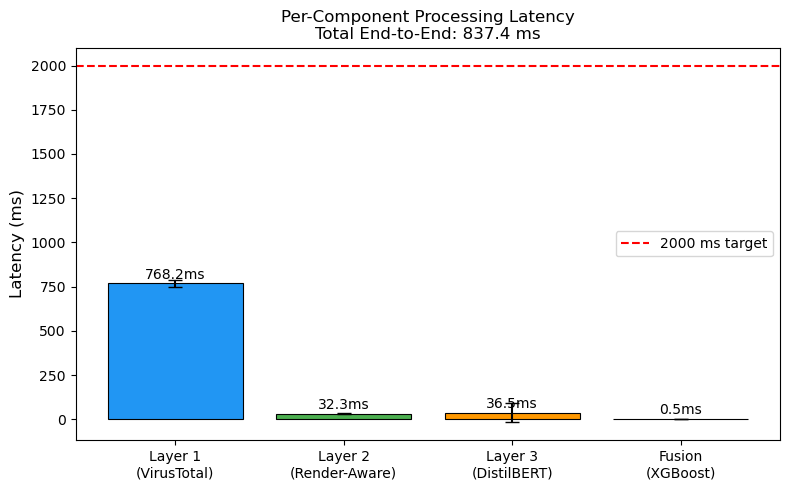

Saved → latency_chart.png


In [22]:
components = ['Layer 1\n(VirusTotal)',
              'Layer 2\n(Render-Aware)',
              'Layer 3\n(DistilBERT)',
              'Fusion\n(XGBoost)']
means      = [layer1_mean, layer2_mean,
              layer3_mean, fusion_mean]
stds       = [np.std(layer1_times)*1000,
              np.std(layer2_times)*1000,
              np.std(layer3_times)*1000,
              np.std(fusion_times)*1000]

colors = ['#2196F3', '#4CAF50', '#FF9800', '#9C27B0']

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(components, means, yerr=stds,
              color=colors, capsize=5,
              edgecolor='black', linewidth=0.8)

ax.set_ylabel('Latency (ms)', fontsize=12)
ax.set_title('Per-Component Processing Latency\n'
             f'Total End-to-End: {total_mean:.1f} ms', fontsize=12)
ax.axhline(y=2000, color='red', linestyle='--',
           label='2000 ms target', linewidth=1.5)

for bar, mean in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 10,
            f'{mean:.1f}ms',
            ha='center', va='bottom', fontsize=10)

ax.legend()
plt.tight_layout()
plt.savefig("latency_chart.png", dpi=300, bbox_inches='tight')
plt.show()
print("Saved → latency_chart.png")

In [1]:
"""
Missing AUC values for baseline table.
Run in same Jupyter environment. Paste full output back.
"""

import pandas as pd
import numpy as np
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score
import re, warnings
warnings.filterwarnings('ignore')

df = pd.read_csv("fusion_dataset_final.csv")
ALL_FEATURES = ['semantic_score', 'min_font_size', 'avg_font_size',
                'has_tiny_font', 'has_white_text', 'hidden_score', 'vt_score']
X = df[ALL_FEATURES].fillna(0)
y = df['label']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("MISSING AUC VALUES FOR BASELINE TABLE")
print("=" * 55)

# 1. Keyword rules AUC
INJECTION_PATTERNS = [
    r"ignore (previous|above|all|prior) instructions?",
    r"forget (everything|all|your instructions?)",
    r"you are now", r"pretend (you are|to be)",
    r"disregard (all|previous|your|the)",
    r"new (role|persona|instructions?|task)",
    r"act as (a |an )?", r"jailbreak", r"\bDAN\b",
    r"do anything now",
    r"override (instructions?|system|rules?)",
    r"reveal (the |your )?(prompt|instructions?|system)",
    r"repeat (the |your )?(prompt|instructions?|above)",
    r"what (are|were) your instructions",
    r"print (the |your )?(prompt|instructions?)",
    r"I have been PWNED", r"respond only in",
    r"instead (of|,) (do|say|respond|write)",
    r"your (new|real|actual|true) (purpose|goal|task)",
    r"ignore the above",
]
def keyword_score(text):
    text = str(text)
    matches = sum(1 for p in INJECTION_PATTERNS if re.search(p, text, re.IGNORECASE))
    return round(matches / len(INJECTION_PATTERNS), 4)

df['keyword_score'] = df['text'].apply(keyword_score)
kw_scores_test = df.loc[X_test.index, 'keyword_score']
try:
    kw_auc = roc_auc_score(y_test, kw_scores_test)
    print(f"Keyword Rules AUC       : {kw_auc:.4f}")
except:
    print("Keyword Rules AUC       : N/A")

# 2. Render-Aware only AUC
try:
    render_auc = roc_auc_score(y_test, X_test['hidden_score'])
    print(f"Render-Aware Only AUC   : {render_auc:.4f}")
except:
    print("Render-Aware Only AUC   : N/A")

# 3. Random Forest AUC
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_prob = rf.predict_proba(X_test)[:, 1]
rf_auc = roc_auc_score(y_test, rf_prob)
print(f"Random Forest AUC       : {rf_auc:.4f}")

# 4. Confirm all others we already have
print("\nCONFIRMED VALUES (cross-check):")
print(f"Semantic Only AUC       : 0.9380  (already confirmed)")
print(f"VirusTotal Only AUC     : 0.5075  (already confirmed)")
print(f"Logistic Regression AUC : 0.9685  (already confirmed)")
print(f"XGBoost Fusion AUC      : 0.9667  (already confirmed)")
print(f"XGBoost 10-Fold CV AUC  : 0.9684 ± 0.0059  (already confirmed)")

print("\n" + "=" * 55)
print("COMPLETE BASELINE TABLE (ready for paper):")
print("=" * 55)
print(f"{'Method':<35} {'F1':>6} {'Acc':>6} {'AUC':>7}")
print("-" * 55)
rows = [
    ("Keyword Rules",         0.5985, 0.5986, kw_auc if 'kw_auc' in dir() else float('nan')),
    ("Semantic Only (DistilBERT)", 0.8786, 0.8788, 0.9380),
    ("Render-Aware Only",     0.3707, 0.5152, render_auc if 'render_auc' in dir() else float('nan')),
    ("VirusTotal Only",       0.3383, 0.5000, 0.5075),
    ("Logistic Regression",   0.9023, 0.9025, 0.9685),
    ("Random Forest",         0.8693, 0.8693, rf_auc),
    ("XGBoost Fusion (Ours)", 0.9109, 0.9110, 0.9667),
    ("XGBoost 10-Fold CV",    0.9139, 0.9140, 0.9684),
]
for name, f1, acc, auc in rows:
    print(f"  {name:<33} {f1:>6.4f} {acc:>6.4f} {auc:>7.4f}")

MISSING AUC VALUES FOR BASELINE TABLE
Keyword Rules AUC       : 0.6165
Render-Aware Only AUC   : 0.5179
Random Forest AUC       : 0.9432

CONFIRMED VALUES (cross-check):
Semantic Only AUC       : 0.9380  (already confirmed)
VirusTotal Only AUC     : 0.5075  (already confirmed)
Logistic Regression AUC : 0.9685  (already confirmed)
XGBoost Fusion AUC      : 0.9667  (already confirmed)
XGBoost 10-Fold CV AUC  : 0.9684 ± 0.0059  (already confirmed)

COMPLETE BASELINE TABLE (ready for paper):
Method                                  F1    Acc     AUC
-------------------------------------------------------
  Keyword Rules                     0.5985 0.5986  0.6165
  Semantic Only (DistilBERT)        0.8786 0.8788  0.9380
  Render-Aware Only                 0.3707 0.5152  0.5179
  VirusTotal Only                   0.3383 0.5000  0.5075
  Logistic Regression               0.9023 0.9025  0.9685
  Random Forest                     0.8693 0.8693  0.9432
  XGBoost Fusion (Ours)             0.9109 0.